In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
import json
import numpy as np

In [3]:
empty_dict = {'crisis': 1,
 'independence': 0,
 'unification': 0,
 'democratic_values': 0,
 'natural_disaster': 0,
 'semiconductors': 0,
 'cultural': 0,
 'pro_Taiwan': 0,
 'against_Taiwan': 0,
 'pro_China': 1,
 'against_China': 0}

empty_dict = {k:np.nan for k in empty_dict.keys()}  #reset or initialize a dictionary’s values
LABELS = list(empty_dict.keys())   # the 11 label columns, used by name below

In [5]:
df = pd.concat([pd.read_pickle(f) for f in glob("raw_labels/*.pkl")])
df = df[ ~df.llm_results.apply(lambda x: "mermaid" in x.content ) ]

def parse_response(r):
    try:
        r = r.content
        return json.loads(r)
    except:
        return empty_dict

df2 = df.llm_results.apply(parse_response).reset_index()
df3 = pd.DataFrame( df2.llm_results.to_list() )

df  = df.reset_index(drop=True)
df3 = df3.reset_index(drop=True)

df = pd.concat((df, df3), axis=1)
df = df[~df.independence.isna()]
df[df3.columns] = df[df3.columns].astype(bool)

In [9]:
df.to_pickle('big_dataframe.pkl')

In [10]:
df2 = df[["language", "media_name", "publish_date", "title" ] + LABELS].copy()
df2["yearmonth"] = df2.publish_date.apply(lambda x: x[:7])
df2.yearmonth = pd.to_datetime(df2.yearmonth)

In [11]:
ind = df2[df2.independence ]
uni = df2[df2.unification ]
semi = df2[df2.semiconductors]
demo = df2[df2.democratic_values]

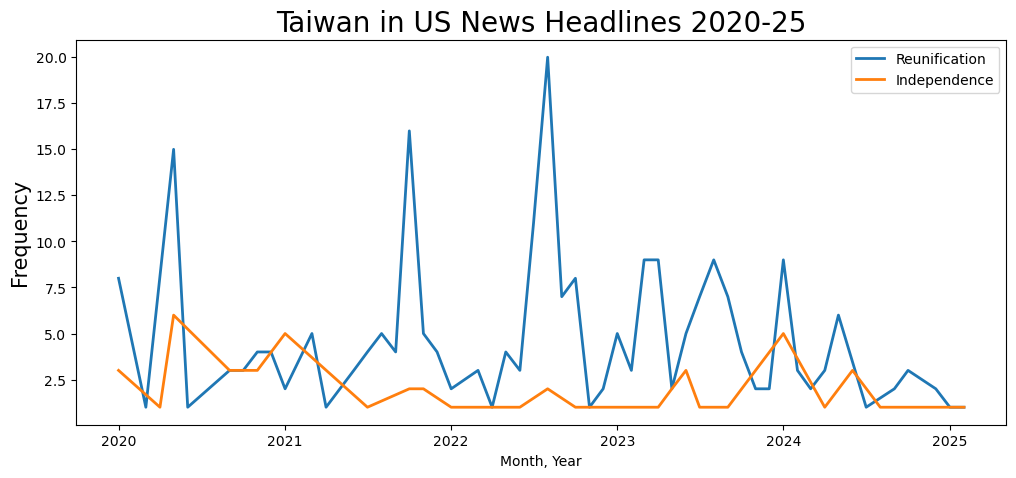

In [14]:
plt.figure(figsize=(12,5))

plt.title("Taiwan in US News Headlines 2020-25",fontsize=20)
plt.ylabel("Frequency",fontsize=15)
plt.xlabel("Month, Year")

x = uni.yearmonth.value_counts().reset_index()
x.columns = ["yearmonth", "freq"]
x = x.sort_values("yearmonth")
plt.plot(x.yearmonth, x.freq, linewidth=2,label = "Reunification")

# x = demo.yearmonth.value_counts().reset_index()
# x.columns = ["yearmonth", "freq"]
# x = x.sort_values("yearmonth")
# plt.plot(x.yearmonth, x.freq, linewidth=2,label = "Democratic_values")


x = ind.yearmonth.value_counts().reset_index()
x.columns = ["yearmonth", "freq"]
x = x.sort_values("yearmonth")
plt.plot(x.yearmonth, x.freq, linewidth=2,label = "Independence")

"""
x = semi.yearmonth.value_counts().reset_index()
x.columns = ["yearmonth", "freq"]
x = x.sort_values("yearmonth")
plt.plot(x.yearmonth, x.freq, linewidth=2,label = "Semiconductors")
"""

# plt.yscale("log")
# x = semi.yearmonth.value_counts().reset_index()
# x.columns = ["yearmonth", "freq"]
# x = x.sort_values("yearmonth")
# plt.plot(x.yearmonth, x.freq, linewidth=2,label = "Semiconductors")

plt.legend()
plt.savefig("time_ind_uni.jpg", dpi=300)

In [9]:
import seaborn as sns

In [10]:
data = df2[LABELS].astype(int)
print(data)

      crisis  independence  unification  democratic_values  natural_disaster  \
0          1             0            0                  0                 0   
1          0             0            0                  1                 0   
2          0             0            0                  0                 0   
3          1             0            0                  1                 0   
4          0             0            0                  0                 0   
...      ...           ...          ...                ...               ...   
7194       0             0            0                  0                 0   
7195       1             0            0                  0                 0   
7196       0             0            0                  0                 0   
7197       0             0            0                  0                 0   
7198       0             0            0                  0                 0   

      semiconductors  cultural  pro_Tai

In [ ]:
data = df2[LABELS].astype(int)
data = data.corr()
clustermap=sns.clustermap(data)

#clustermap.ax_heatmap.set_title("Correlations in US Media Portrayal of Taiwan", fontsize=20,pad=120 )
# Get the reordered indices from the dendrogram
xticks = clustermap.dendrogram_col.reordered_ind
yticks = clustermap.dendrogram_row.reordered_ind

# Get the reordered correlation matrix
corr = data  # `data` is already the correlation matrix (it was being correlated a second time)
reordered_corr = corr.iloc[yticks, xticks]

# Annotate the heatmap: add correlation coefficients
ax = clustermap.ax_heatmap
for i in range(reordered_corr.shape[0]):
    for j in range(reordered_corr.shape[1]):
        coeff = reordered_corr.iloc[i, j]
        ax.text(j+0.5, i+0.5, f"{coeff:.2f}", ha='center', va='center', color='white', fontsize=8)


clustermap.savefig("my_clustermap_annotated.jpg", dpi=300)


/var/folders/25/j16dq7hn65352nl40xvvqm6c0000gn/T/ipykernel_2040/463097452.py:39: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  stars = pval_matrix.applymap(star_significance)


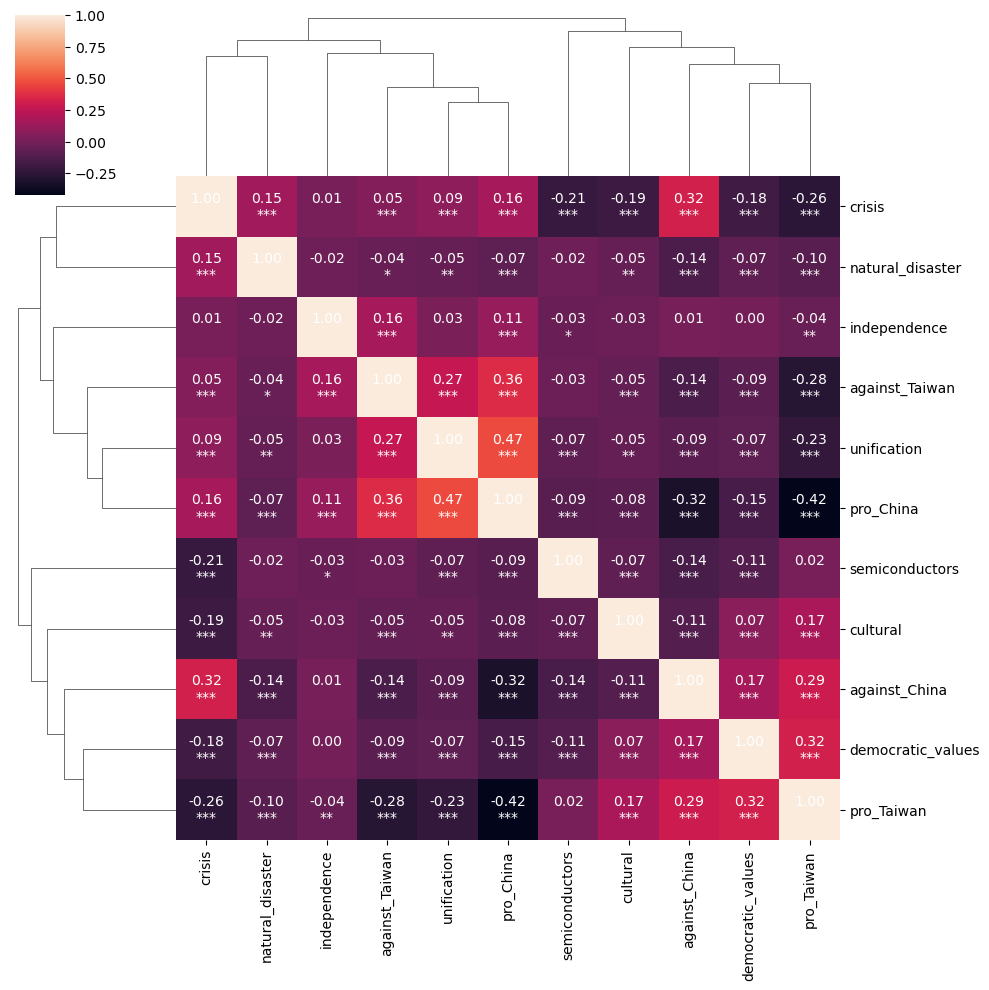

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr

# 1. Prepare your data
data = df2[LABELS].astype(int)

# 2. Calculate correlation matrix
corr = data.corr()

# 3. Function to calculate p-values matrix for correlations
def calculate_pvalues(df):
    cols = df.columns
    pvals = pd.DataFrame(np.ones((len(cols), len(cols))), index=cols, columns=cols)
    for i in range(len(cols)):
        for j in range(i+1, len(cols)):
            col1 = cols[i]
            col2 = cols[j]
            _, p = pearsonr(df[col1], df[col2])
            pvals.loc[col1, col2] = p
            pvals.loc[col2, col1] = p
    return pvals

pval_matrix = calculate_pvalues(data)

# 4. Function to get significance stars from p-values
def star_significance(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.01:
        return '**'
    elif p <= 0.05:
        return '*'
    else:
        return ''

stars = pval_matrix.map(star_significance)   # DataFrame.applymap was removed in pandas 3

# 5. Create cluster map from correlation matrix
clustermap = sns.clustermap(corr)

# 6. Get reordered indices after clustering
xticks = clustermap.dendrogram_col.reordered_ind
yticks = clustermap.dendrogram_row.reordered_ind

# 7. Reorder correlation matrix and stars to match clustered layout
reordered_corr = corr.iloc[yticks, xticks]
reordered_stars = stars.iloc[yticks, xticks]

# 8. Annotate the heatmap with correlation coefficients and significance stars
ax = clustermap.ax_heatmap

for i in range(reordered_corr.shape[0]):
    for j in range(reordered_corr.shape[1]):
        coeff = reordered_corr.iloc[i, j]
        star = reordered_stars.iloc[i, j]
        # Offset text a bit for readability (adjust as you like)
        ax.text(j + 0.5, i + 0.5, f"{coeff:.2f}\n{star}",
                ha='center', va='center', color='white', fontsize=10)

# 9. Save figure
clustermap.savefig("my_clustermap_p.jpg", dpi=300)
plt.show()

In [48]:
df2.media_name.value_counts()

media_name
reuters.com        378
ibtimes.com        242
benzinga.com       239
rttnews.com        218
newsweek.com       164
                  ... 
therealnews.com      1
sbnation.com         1
gazettenet.com       1
elnuevodia.com       1
cleveland.com        1
Name: count, Length: 151, dtype: int64